# 05 · Did it work?

This replays every morning from 1 September to 20 December 2024, months the model never saw while
it was being built. On the first of each month every method learns from what was known by then, and
every morning at 8am it orders each business's waiting quotes. Only afterwards do I look up which
quotes said yes. A morning counts when the owner has a real choice: at least two quotes waiting for
one call.

The ranges come from re-running each comparison 1,000 times on random re-draws of the businesses
and keeping the middle 95%. Whole businesses are re-drawn because one business's mornings are alike.

In [1]:
import sys

sys.path.insert(0, "../scripts")

import pandas as pd
from IPython.display import Image, display

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

import figures
import sensitivity
import style

from quote_followup import backtest

ev = backtest.evaluate(quotes, settings)

Two scores for each way of ordering, with *calls* the number of quotes the owner calls that morning:
**dollars won** is the share of what the best possible pick would have won, added up over every
morning; **yes rate** is how often the called quote said yes.

In [2]:
backtest.for_people(
    ev.summary[
        [
            "scorer",
            "k",
            "dollar_capture",
            "dollar_capture_lo",
            "dollar_capture_hi",
            "hit_rate",
            "hit_rate_lo",
            "hit_rate_hi",
        ]
    ]
).round(3)

,way of ordering,calls,dollars won,dollars low,dollars high,yes rate,yes low,yes high
0,Our list: chance x amount,1,0.809,0.781,0.836,0.359,0.342,0.376
1,"Our list, by chance only",1,0.622,0.586,0.657,0.443,0.426,0.459
2,"Our list, ignoring days without a reply",1,0.660,0.618,0.697,0.219,0.204,0.237
3,Days without a reply x amount,1,0.811,0.781,0.839,0.359,0.342,0.376
4,Biggest quote first,1,0.645,0.599,0.685,0.210,0.194,0.228
5,Newest quote first,1,0.640,0.601,0.676,0.425,0.409,0.442
6,Random order,1,0.377,0.342,0.409,0.245,0.229,0.262
7,Our list: chance x amount,3,0.913,0.881,0.942,0.307,0.284,0.332
8,"Our list, by chance only",3,0.851,0.816,0.891,0.340,0.316,0.363
9,"Our list, ignoring days without a reply",3,0.843,0.808,0.872,0.216,0.195,0.237


## H1 · Does it beat what an owner would do anyway?

In [3]:
backtest.for_people(ev.comparisons.iloc[:2]).round(3)

,this order,compared with,measure,calls,difference,low,high
0,Our list: chance x amount,Newest quote first,dollars won,1,0.169,0.134,0.202
1,Our list: chance x amount,Biggest quote first,dollars won,1,0.164,0.129,0.200


**Yes.** Calling the top quote on our list wins 16 to 17 points more of the available dollars than
calling the newest or the biggest quote, and the whole range stays well above zero.

I measure total dollars because that's what an owner banks. The average of each morning's share
tells a different story, because it counts a \$60 morning the same as a \$6,000 one:

In [4]:
ev.first_measure.round(3).rename("average of each morning's share")

scorer
Our list: chance x amount                  0.665
Our list, by chance only                   0.726
Our list, ignoring days without a reply    0.413
Days without a reply x amount              0.664
Biggest quote first                        0.396
Newest quote first                         0.710
Random order                               0.398
Name: average of each morning's share, dtype: float64

On that average, our list (0.665) trails *newest quote first* (0.710): it wins the big mornings and
gives up some small ones.

## H2 · Does knowing the quote make the order better?

The rival is the toughest simple one: how often quotes that have waited this long end in a yes,
times the amount. It knows nothing else about the quote.

In [5]:
backtest.for_people(ev.comparisons.iloc[2:4]).round(4)

,this order,compared with,measure,calls,difference,low,high
2,Our list: chance x amount,Days without a reply x amount,dollars won,1,-0.0021,-0.0179,0.0119
3,Our list: chance x amount,Days without a reply x amount,dollars won,3,-0.0027,-0.0158,0.0087


**No, not for the order.** The simple rival does just as well, within 2 points either way. What puts
the right quote at the top is how long it has waited and how much it's worth.

Knowing the quote does help when the goal is the number of yeses rather than dollars:

In [6]:
backtest.for_people(ev.comparisons.iloc[4:]).round(4)

,this order,compared with,measure,calls,difference,low,high
4,Our list: chance x amount,Newest quote first,yes rate,1,-0.0659,-0.0765,-0.0549
5,"Our list, by chance only",Newest quote first,yes rate,1,0.0180,0.0118,0.0238
6,"Our list, by chance only",Newest quote first,yes rate,3,0.0020,-0.0006,0.0046


Ordered by chance alone, our model gets 1.8 points more first calls ending in a yes than *newest
quote first*; with three calls a morning the gain disappears. Ordered by dollars, it gets 6.6 points
fewer yeses, because it goes after bigger, less certain quotes. Which matters more is the owner's
call, and the tool can order either way.

## H3 · Is the chance on the screen right for each kind of quote?

In [7]:
backtest.for_people(ev.quality).round(3)

,our model,days waiting only
quote-mornings scored,75406.000,75406.000
different quotes,9522.000,9522.000
"AUC, every waiting morning counted",0.870,0.849
AUC of days waiting alone,0.849,0.849
"AUC, each quote counted once",0.691,0.542
"AUC among quotes the same age, lowest",0.665,0.496
"AUC among quotes the same age, highest",0.693,0.634
log loss (lower is better),0.374,0.396
Brier score (lower is better),0.121,0.130
average gap between chance and reality,0.007,0.003


**Mostly yes, and this is what knowing the quote is for.** On average both are right, which is why
the average alone can't tell them apart. Group by group, the simple rival misses in 39 of 101 groups
by more than luck explains; our model misses in 3. Our model also tells apart quotes that have
waited the same time, and quotes on their first morning.

The 0.87 AUC in the first row counts a quote once for every morning it waited, so a quote ignored for
20 days counts 20 times, mostly as an easy "no". The once-per-quote and same-age figures are the
fair ones.

The groups our model still misses:

In [8]:
threshold = ev.quality.loc["subgroup_z_threshold", "our model"]
ev.subgroups[ev.subgroups["z"].abs() > threshold].round(3)

,workflow_type,split,level,age_band,rows,quotes,predicted,observed,gap,z
48,recurring,customer_channel,marketplace,"(14.0, 30.0]",1971,140,0.006,0.001,-0.005,-4.492
69,recurring,customer_channel,repeat_offline,"(3.0, 7.0]",200,79,0.547,0.790,0.243,4.171
97,recurring,send_speed,within a day,"(1.0, 3.0]",1512,926,0.633,0.689,0.056,3.574


Two are recurring quotes from repeat customers, or sent within a day, that have waited one to seven
days: the model still reads their silence as slightly worse news than it is. The third is a group of
marketplace leads quiet for over two weeks (0.6% predicted, 0.1% real), which stands out
statistically but is under a point.

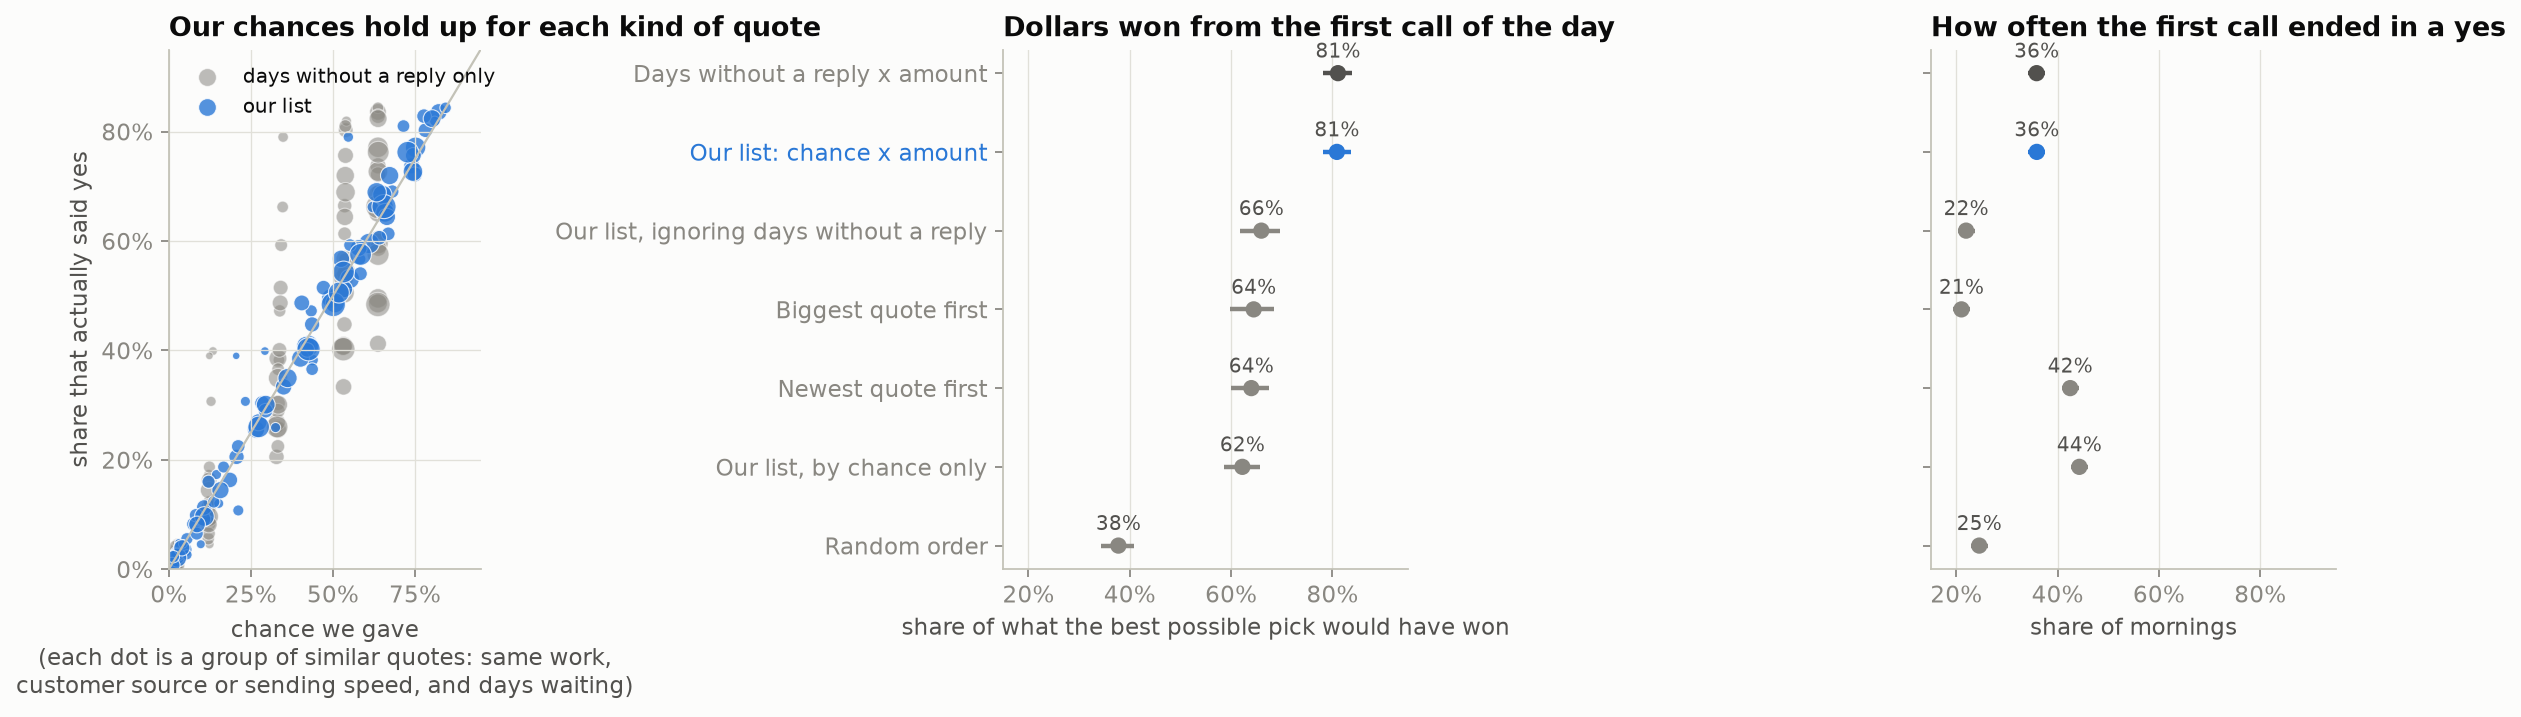

In [9]:
style.apply()
figures.evidence(ev.summary, ev.subgroups, ev.simple_subgroups)
display(Image("../assets/evidence.png"))

## Does it hold month to month?

In [10]:
ev.monthly.query("k == 1").pivot(index="month", columns="scorer", values="dollar_capture").round(3)

scorer,Biggest quote first,Days without a reply x amount,Newest quote first,"Our list, by chance only","Our list, ignoring days without a reply",Our list: chance x amount,Random order
month,,,,,,,
2024-09,0.689,0.858,0.654,0.625,0.702,0.831,0.378
2024-10,0.675,0.844,0.691,0.699,0.692,0.847,0.380
2024-11,0.575,0.800,0.646,0.628,0.586,0.802,0.379
2024-12,0.658,0.748,0.568,0.535,0.678,0.758,0.373


Our list is ahead of both rules of thumb every month.

## Would a different judgement call change the answer?

Each row changes one decision and reruns the whole replay.

In [11]:
sensitivity.run(quotes, settings).round(3)

,what changed,our list,days waiting x amount,best rule of thumb,its dollars won,our lead over it,lead low,lead high,lead over days waiting x amount,average chance gap,groups missed beyond luck
0,nothing (as built),0.809,0.811,Biggest quote first,0.645,0.164,0.123,0.203,-0.002,0.007,3
1,stale open quotes counted as lost,0.803,0.802,Newest quote first,0.642,0.161,0.128,0.193,0.001,0.005,2
2,"wait 60 days, not 45, before learning from a quote",0.807,0.811,Biggest quote first,0.645,0.163,0.123,0.202,-0.004,0.007,3
3,"reply speeds may use groups of 50 quotes, not 200",0.809,0.811,Biggest quote first,0.645,0.164,0.123,0.203,-0.002,0.007,3
4,reply speeds also learned by customer source,0.811,0.811,Biggest quote first,0.645,0.166,0.128,0.205,0.000,0.007,5


Counting the stale "open" quotes as lost, waiting 60 days instead of 45 before learning from a quote,
letting reply speeds use smaller groups, or learning them by customer source: none of it changes the
picture.